In [1]:
# %% [1. RL GRIDWORLD ENVIRONMENT]
import numpy as np
import matplotlib.pyplot as plt

ROWS, COLS = 4, 4
START = (0, 0)
GOAL = (3, 3)
PIT = (1, 1)
WALL = (2, 2)

ACTIONS = ['U', 'D', 'L', 'R']
ARROWS = {'U': '↑', 'D': '↓', 'L': '←', 'R': '→'}
MOVES = {'U': (-1, 0), 'D': (1, 0), 'L': (0, -1), 'R': (0, 1)}

def step(state, action):
    if state in [GOAL, PIT]:
        return state, 0.0, True
    dr, dc = MOVES[action]
    nr, nc = state[0] + dr, state[1] + dc
    if nr < 0 or nr >= ROWS or nc < 0 or nc >= COLS or (nr, nc) == WALL:
        nr, nc = state
    next_state = (nr, nc)
    if next_state == GOAL:
        return next_state, 10.0, True
    elif next_state == PIT:
        return next_state, -10.0, True
    return next_state, -0.1, False

def show_policy(policy_grid, title):
    print(f"\n=== {title} ===")
    for r in range(ROWS):
        row_str = []
        for c in range(COLS):
            s = (r, c)
            if s == GOAL: row_str.append(' G ')
            elif s == PIT: row_str.append(' P ')
            elif s == WALL: row_str.append(' # ')
            else: row_str.append(f' {policy_grid[r][c]} ')
        print(' '.join(row_str))

print("States: 16 | Start: (0,0) | Goal (+10): (3,3) | Pit (-10): (1,1) | Wall: (2,2) | Step: -0.1")


States: 16 | Start: (0,0) | Goal (+10): (3,3) | Pit (-10): (1,1) | Wall: (2,2) | Step: -0.1


SARSA Max Q-Value Grid:
 [[ 4.29  2.3  -0.04  0.06]
 [ 5.46  0.    0.48  1.84]
 [ 6.54  7.21  0.    6.86]
 [ 7.38  8.75 10.    0.  ]]

=== SARSA Learned Policy ===
 ↓   ←   ↓   ↓ 
 ↓   P   →   ↓ 
 ↓   ↓   #   ↓ 
 →   →   →   G 


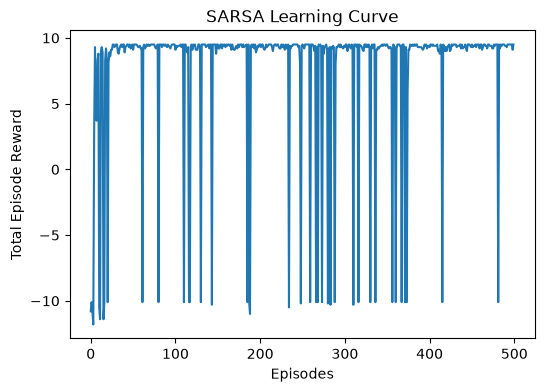

In [2]:
# %% [2B. SARSA - ON-POLICY TD CONTROL]
alpha = 0.1
gamma = 0.9
epsilon = 0.2
episodes = 500

Q = np.zeros((ROWS, COLS, len(ACTIONS)))
rewards_history = []

def choose_action(state):
    if np.random.rand() < epsilon:
        return np.random.randint(len(ACTIONS))
    return int(np.argmax(Q[state]))

for _ in range(episodes):
    s = START
    a_idx = choose_action(s)
    total_reward = 0.0
    done = False
    while not done:
        ns, rew, done = step(s, ACTIONS[a_idx])
        na_idx = choose_action(ns)
        target = rew + (0.0 if done else gamma * Q[ns][na_idx])
        Q[s][a_idx] += alpha * (target - Q[s][a_idx])
        s, a_idx = ns, na_idx
        total_reward += rew
    rewards_history.append(total_reward)

sarsa_policy = [[ARROWS[ACTIONS[int(np.argmax(Q[r, c]))]] for c in range(COLS)] for r in range(ROWS)]
print("SARSA Max Q-Value Grid:\n", np.round(np.max(Q, axis=2), 2))
show_policy(sarsa_policy, "SARSA Learned Policy")

plt.figure(figsize=(6, 4))
plt.plot(rewards_history)
plt.xlabel('Episodes')
plt.ylabel('Total Episode Reward')
plt.title('SARSA Learning Curve')
plt.show()
